# Fundamentos de Ciencia de Datos - FCEx - UNICEN

# Unidad 6: Clustering

## Clase Práctica 7: Métodos de clustering

Este Colab corresponde a la séptima clase práctica del curso Fundamentos de Ciencia de Datos, que se dicta en el 4to año de la carrera de Ingeniería de Sistemas de la Facultad de Ciencias Exactas de la UNICEN. Ya vamos terminando!

La clase de hoy se enfoca en clustering, o agrupamiento. Algoritmos que son una belleza, porque los acercan un poco más a entender realmente la geometría de los datos: quién está cerca de quién, quién está lejos, y qué representa cada grupo de muestras cercanas.

Los algoritmos de clustering nos permiten hacer análisis no supervisado de los datos, a través de una serie de estrategias que asignan a cada muestra a un agrupamiento o cluster.

Muy seguido van a encontrar en los libros la idea de "análisis de cluster". ¡Y está bien! Porque cuando estudiamos agrupamientos, estos no necesariamente tienen semántica asociada. Un grupo cercano en el espacio de características seguramente significa algo, pero no sabremos qué hasta que no estudiemos qué pasa con las características ahí dentro. Así que los métodos de clustering son siempre un primer paso para empezar primero a estudiar qué similitudes existen entre las muestras, y después sacar conclusiones más ricas que nos ayuden en la toma de decisiones.

Clustering está en el centro del famoso Big Data que oímos nombrar en todas partes. Usando estas técnicas podemos hallar relaciones entre los datos que quizá desconocíamos, y utilizar esas nuevas conclusiones como guía para tal o cual aplicación.

## 1 - Preparamos algunos datos

En esta unidad vamos a ver algunas de las estrategias de clustering más populares, utilizando datos de la Organización Mundial de la Salud (WHO) sobre expectativa de vida en numerosos países. La info sobre los datos está disponible en [este sitio](https://www.kaggle.com/kumarajarshi/life-expectancy-who).

Lo primero que haremos será descargarlos e imprimir algunas muestras:

In [ ]:
!pip install wget

#from sklearn.cluster import KMeans
import wget
import pandas as pd

from os import path

# inicializamos un diccionario donde guardaremos el dataset
dataset = dict()
dataset['url'] = 'https://raw.githubusercontent.com/ignaciorlando/duia-ml-datasets/master/LifeExpectancyWHO/Life Expectancy Data.csv'
dataset['extension'] = '.csv'
dataset['filename'] = 'life_expectancy' + dataset['extension']
if not path.exists(dataset['filename']):  # descargar solamente si no existe
  wget.download(dataset['url'], dataset['filename'])
else:
  print('El archivo {} ya existe.'.format(dataset['filename']))

# accedemos a los datos usando Pandas
original_table = pd.read_table(dataset['filename'],sep=',')
original_table.head()


  Preparing metadata (setup.py) ... done
  Created wheel for wget: filename=wget-3.2-py3-none-any.whl size=9655 sha256=233d47c32100972d7a38f593d362cf1164e443400d0d1f10a662dabf6a53a393
  Stored in directory: /root/.cache/pip/wheels/01/46/3b/e29ffbe4ebe614ff224bad40fc6a5773a67a163251585a13a9
Successfully built wget


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


El archivo contiene una serie de estadísticas sobre muchos países, categorizadas por año de extracción. Veamos de qué se trata:

In [ ]:
print(original_table.columns)
print(original_table['Country'].unique())


Index(['Country', 'Year', 'Status', 'Life expectancy ', 'Adult Mortality',
       'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B',
       'Measles ', ' BMI ', 'under-five deaths ', 'Polio', 'Total expenditure',
       'Diphtheria ', ' HIV/AIDS', 'GDP', 'Population',
       ' thinness  1-19 years', ' thinness 5-9 years',
       'Income composition of resources', 'Schooling'],
      dtype='object')
['Afghanistan' 'Albania' 'Algeria' 'Angola' 'Antigua and Barbuda'
 'Argentina' 'Armenia' 'Australia' 'Austria' 'Azerbaijan' 'Bahamas'
 'Bahrain' 'Bangladesh' 'Barbados' 'Belarus' 'Belgium' 'Belize' 'Benin'
 'Bhutan' 'Bolivia (Plurinational State of)' 'Bosnia and Herzegovina'
 'Botswana' 'Brazil' 'Brunei Darussalam' 'Bulgaria' 'Burkina Faso'
 'Burundi' "Côte d'Ivoire" 'Cabo Verde' 'Cambodia' 'Cameroon' 'Canada'
 'Central African Republic' 'Chad' 'Chile' 'China' 'Colombia' 'Comoros'
 'Congo' 'Cook Islands' 'Costa Rica' 'Croatia' 'Cuba' 'Cyprus' 'Czechia'
 "Democratic People's

Las features incluyen:
* El estado del país (si es desarrollado o no desarrollado).
* La expectativa de vida (en años).
* La mortalidad adulta.
* La cantidad de muertes de niñxs por cada 1000 habitantes.
* La cantidad de alcohol consumido por mayores de 15 años per cápita (en litros de alcohol puro).
* El porcentaje del PBI per cápita invertido en salud.
* El porcentaje de vacunación contra la hepatitis B en niñxs de 1 año.
* El número de casos de sarampión reportado por cada 1000 habitantes.
* Índice de masa corporal promedio de la población
* Número de muertes por debajo de los 5 años cada 1000 habitantes.
* El porcentaje de vacunación contra la polio en niñxs de 1 año.
* El porcentaje de inversión en salud del Estado en función del presupuesto total del país.
* El porcentaje de vacunación contra la difteria en niñxs de 1 año.
* La cantidad de muertes por VIH/SIDA cada 1000 habitantes en niñxs de 0 a 4 años.
* El producto bruto interno per cápita.
* La cantidad de habitantes del país.
* Prevalencia de flacura entre niñxs y adolescentes de 10 a 19 años.
* Prevalencia de flacura entre niñxs de 5 a 9 años.
* Índice de desarrollo humano (en término de la composición del ingreso).
* Número de años de escolarización.

Como verán, un montón de información técnica sobre los diferentes países.
Las estadísticas vienen por año, así que lo que haremos será quedarnos con un año particular (el 2015, que es el último registrado). Además, necesitamos convertir el único dato categórico a números. No usaremos one-hot encoding porque en este bello mundo desigual (por bello me refiero a horrendo), un país desarrollado es más que uno en desarrollo. Finalmente, eliminaremos las columnas "País" y "Año" de las matrices, porque no nos interesan.

In [ ]:
# nos quedamos solamente con la data de 2015
data_2015 = original_table[original_table['Year'] == 2015]
# convertimos la columna status
data_2015['Status'] = data_2015['Status'].apply(lambda x: 1 if x == 'Developed' else 0)

data_2015.head()


/tmp/ipython-input-1236665644.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_2015['Status'] = data_2015['Status'].apply(lambda x: 1 if x == 'Developed' else 0)


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,0,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
16,Albania,2015,0,77.8,74.0,0,4.60,364.975229,99.0,0,...,99.0,6.00,99.0,0.1,3954.227830,28873.0,1.2,1.3,0.762,14.2
32,Algeria,2015,0,75.6,19.0,21,NaN,0.000000,95.0,63,...,95.0,NaN,95.0,0.1,4132.762920,39871528.0,6.0,5.8,0.743,14.4
48,Angola,2015,0,52.4,335.0,66,NaN,0.000000,64.0,118,...,7.0,NaN,64.0,1.9,3695.793748,2785935.0,8.3,8.2,0.531,11.4
64,Antigua and Barbuda,2015,0,76.4,13.0,0,NaN,0.000000,99.0,0,...,86.0,NaN,99.0,0.2,13566.954100,NaN,3.3,3.3,0.784,13.9


El dataset también reporta algunos datos faltantes (que aparecen como NaNs), así que lo que haremos será remover las features para las que no tengamos datos para todos los países.

In [ ]:
# eliminamos columnas con NaNs
data_2015 = data_2015.dropna(axis=1)
data_2015

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,percentage expenditure,Measles,under-five deaths,Polio,Diphtheria,HIV/AIDS
0,Afghanistan,2015,0,65.0,263.0,62,71.279624,1154,83,6.0,65.0,0.1
16,Albania,2015,0,77.8,74.0,0,364.975229,0,0,99.0,99.0,0.1
32,Algeria,2015,0,75.6,19.0,21,0.000000,63,24,95.0,95.0,0.1
48,Angola,2015,0,52.4,335.0,66,0.000000,118,98,7.0,64.0,1.9
64,Antigua and Barbuda,2015,0,76.4,13.0,0,0.000000,0,0,86.0,99.0,0.2
...,...,...,...,...,...,...,...,...,...,...,...,...
2858,Venezuela (Bolivarian Republic of),2015,0,74.1,157.0,9,0.000000,0,10,87.0,87.0,0.1
2874,Viet Nam,2015,0,76.0,127.0,28,0.000000,256,35,97.0,97.0,0.1
2890,Yemen,2015,0,65.7,224.0,37,0.000000,468,47,63.0,69.0,0.1
2906,Zambia,2015,0,61.8,33.0,27,0.000000,9,40,9.0,9.0,4.1


Nos queda finalmente normalizar los datos y dejar bien armados los campos del dataset. En este caso lo haremos utilizando normalización por rangos, según el valor mínimo/máximo de cada columna. Para eso vamos a usar la clase ```MinMaxScaler``` de Sklearn, que está piola porque es bastante sencilla de usar:

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

# Seleccionamos las columnas numéricas para la normalización
numeric_cols = data_2015.select_dtypes(include=np.number).columns

# Creamos un objeto MinMaxScaler
scaler = MinMaxScaler()

# Ajustamos el scaler a los datos y transformamos los datos
data_2015[numeric_cols] = scaler.fit_transform(data_2015[numeric_cols])

# Imprimimos el DataFrame con los datos normalizados
data_2015.head()


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,percentage expenditure,Measles,under-five deaths,Polio,Diphtheria,HIV/AIDS
0,Afghanistan,0.0,0.0,0.378378,0.542443,0.068132,0.1953,0.012767,0.075455,0.010638,0.634409,0.000000
16,Albania,0.0,0.0,0.724324,0.151139,0.000000,1.0000,0.000000,0.000000,1.000000,1.000000,0.000000
32,Algeria,0.0,0.0,0.664865,0.037267,0.023077,0.0000,0.000697,0.021818,0.957447,0.956989,0.000000
48,Angola,0.0,0.0,0.037838,0.691511,0.072527,0.0000,0.001305,0.089091,0.021277,0.623656,0.195652
64,Antigua and Barbuda,0.0,0.0,0.686486,0.024845,0.000000,0.0000,0.000000,0.000000,0.861702,1.000000,0.010870


Ya con estos datos bien listos, planteemos la siguiente pregunta: ¿qué similitudes existen entre los países en términos de sus indicadores sanitarios?

## 2 - K-Means

El algoritmo de K-means es el más comunmente utilizado en problemas de clustering. Se basa en descubrir K centroides en los datos que me representen los diferentes agrupamientos que puedan llegar a existir, de manera iterativa y basándose en la distancia entre las muestras.

Inicialmente se eligen al azar K muestras que operarán como centroides, y luego se realiza un proceso iterativo que consiste en dos fases:

1. Fase de asignación: cada muestra es asignada al cluster correspondiente al centroide más cercano.
2. Fase de actualización: se actualiza el centroide tomando la media de las muestras dentro del cluster.

Este proceso se repite hasta estabilizar lo que se conoce como **suma de distancias cuadradas**, que no es más que la suma de las distancias al cuadrado de cada muestra al centroide asociado a su cluster. Se espera que cuando esto deje de variar, estemos ante una posible solución.

En Sklearn, el algoritmo de K-means se llama ```KMeans``` y viene dentro del paquete ```cluster```. El hiperparámetro más importante es ```n_clusters```, que no es más que el valor de K. Vamos a generar una primera partición en 4 clusters y ver los resultados que obtenemos.

In [ ]:
from sklearn.cluster import KMeans

# separamos las features de los nombres de los países
countries = data_2015['Country']
features_data_2015 = data_2015.drop(columns=['Country', 'Year'])

# inicializamos un objeto de la clase KMeans con el modelo
kmeans = KMeans(n_clusters=4, verbose=0, random_state=10)
# lo aplicamos sobre nuestros datos para hallar los centroides
kmeans.fit(features_data_2015)
# y obtenemos los clusters a los que fueron asignadas las muestras
clusters_kmeans = kmeans.predict(features_data_2015)
print(clusters_kmeans)

[2 0 0 2 0 0 0 1 1 0 0 0 0 0 0 1 0 3 0 0 0 3 0 0 1 0 3 3 0 0 3 0 3 3 0 0 0
 0 2 0 1 0 1 1 0 3 1 3 0 0 0 0 2 0 0 3 0 0 0 2 3 0 1 3 0 0 2 2 3 0 2 0 1 1
 0 2 0 2 1 0 1 0 1 0 0 3 2 0 0 0 1 0 3 2 0 1 1 0 3 0 0 3 1 0 0 0 0 0 0 0 2
 0 3 2 1 1 0 0 3 1 0 0 0 3 0 2 2 1 1 0 0 0 1 0 0 0 0 0 0 0 0 0 0 3 1 1 1 0
 2 3 2 1 0 0 0 3 1 1 2 0 0 0 0 3 2 0 0 0 0 3 2 0 1 3 1 0 0 0 0 0 3 2 3]


Obviamente lo que estamos viendo es el cluster correspondiente a cada país, según el orden en el que se los presentamos a KMeans en la matriz de diseño. Si queremos saber qué países están dentro de cada cluster, tenemos que hacer un filtrado:

In [ ]:
import pandas as pd

# Creamos un DataFrame con los países y los clusters asignados
cluster_df = pd.DataFrame({'Country': countries, 'Cluster': clusters_kmeans})

# Imprimimos los países de cada cluster
for cluster_num in range(4):
  print(f"\nCluster {cluster_num}:")
  print(cluster_df[cluster_df['Cluster'] == cluster_num]['Country'].tolist())



Cluster 0:
['Albania', 'Algeria', 'Antigua and Barbuda', 'Argentina', 'Armenia', 'Azerbaijan', 'Bahamas', 'Bahrain', 'Bangladesh', 'Barbados', 'Belarus', 'Belize', 'Bhutan', 'Bolivia (Plurinational State of)', 'Bosnia and Herzegovina', 'Brazil', 'Brunei Darussalam', 'Burkina Faso', 'Cabo Verde', 'Cambodia', 'Canada', 'Chile', 'China', 'Colombia', 'Comoros', 'Costa Rica', 'Cuba', "Democratic People's Republic of Korea", 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Eritrea', 'Estonia', 'Fiji', 'Finland', 'France', 'Georgia', 'Greece', 'Grenada', 'Guyana', 'Honduras', 'India', 'Iran (Islamic Republic of)', 'Israel', 'Jamaica', 'Jordan', 'Kazakhstan', 'Kuwait', 'Kyrgyzstan', "Lao People's Democratic Republic", 'Lebanon', 'Libya', 'Madagascar', 'Malaysia', 'Maldives', 'Mauritania', 'Mauritius', 'Mexico', 'Micronesia (Federated States of)', 'Mongolia', 'Montenegro', 'Morocco', 'Myanmar', 'Nicaragua', 'Niger', 'Oman', 'Pakistan', 'Panama', 'Paraguay', 'Qatar', 'Republic of Korea

Este primer agrupamiento nos permite ver algunas cosas interesantes. Por ejemplo, en el cluster 3 vemos que se agruparon la gran mayoría de los países africanos. En el cluster 2, otros países de África y algunos de Asia, Europa del Este y el norte de Sudamérica y el Caribe. En el cluster 0 (el más grande) vemos países de un montón de regiones del mundo. Finalmente, en el cluster 1 vemos un gran número de países europeos junto a USA, Australia, entre otros.
**¿Qué nos estará planteando esta partición?** Otra buena oportunidad para conversar sobre inequidades sanitarias en el mundo.

Algo que se suele hacer a menudo es representar los resultados en un scatter plot. Nuevamente, como tenemos una alta dimensionalidad en las características, lo más conveniente es explotar un t-SNE o PCA, y trasladar los resultados a dos dimensiones:


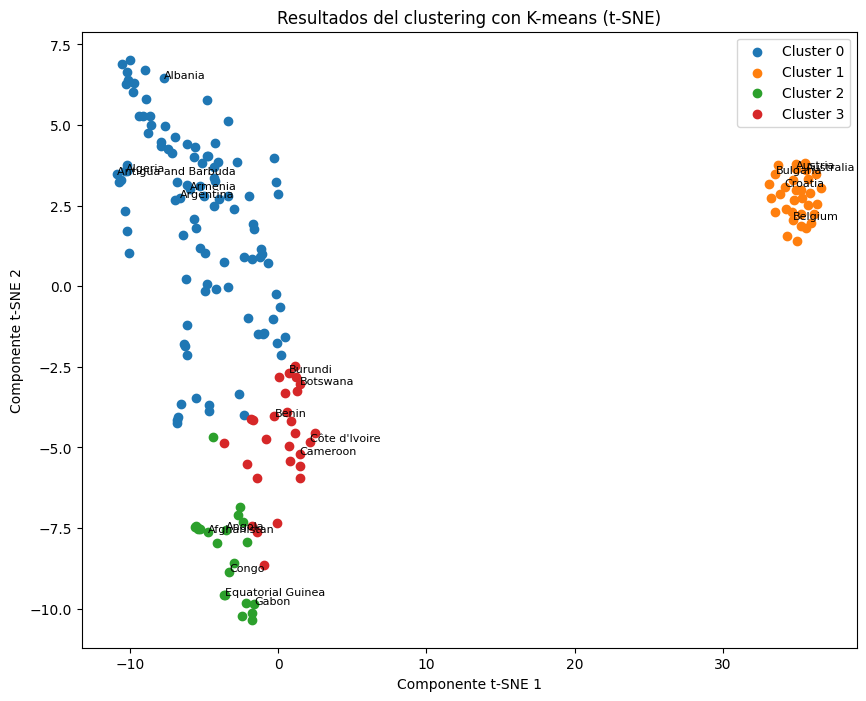

In [ ]:
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

# Reducir la dimensionalidad de los datos usando t-SNE
tsne = TSNE(n_components=2, random_state=42)
tsne_results = tsne.fit_transform(features_data_2015)

# Crear un DataFrame con los resultados de t-SNE y los clusters
tsne_df = pd.DataFrame({'x': tsne_results[:, 0], 'y': tsne_results[:, 1], 'Cluster': clusters_kmeans, 'Country': countries})

# Graficar los resultados de t-SNE, coloreando los puntos según el cluster
plt.figure(figsize=(10, 8))
for cluster_num in range(4):
  plt.scatter(tsne_df[tsne_df['Cluster'] == cluster_num]['x'], tsne_df[tsne_df['Cluster'] == cluster_num]['y'], label=f'Cluster {cluster_num}')

  # Seleccionar 5 países para etiquetar en cada cluster, incluyendo Argentina si está presente
  countries_to_label = tsne_df[tsne_df['Cluster'] == cluster_num]['Country'].tolist()
  if 'Argentina' in countries_to_label:
    countries_to_label.remove('Argentina')
    countries_to_label = ['Argentina'] + countries_to_label[:4]
  else:
    countries_to_label = countries_to_label[:5]

  for country in countries_to_label:
    row = tsne_df[(tsne_df['Cluster'] == cluster_num) & (tsne_df['Country'] == country)]
    if not row.empty:
      plt.text(row['x'].values[0], row['y'].values[0], country, fontsize=8)

plt.xlabel('Componente t-SNE 1')
plt.ylabel('Componente t-SNE 2')
plt.title('Resultados del clustering con K-means (t-SNE)')
plt.legend()
plt.show()


En principio observamos que el cluster 1 (el que incluye a la gran mayoría de los países desarrollados) está bien separado de los otros 3, lo cual tiene sentido teniendo en cuenta sus posibilidades económicas. Luego vemos que los clusters 2 y 3, que corresponden a países que sabemos que son muy pobres, están muy cerca, y en valores bajos de ambos componentes del t-SNE. Luego, vemos que hay una transición hacia el cluster 0, en el que se encuentra Argentina.

En principio podemos sospechar que nuestra elección de K estuvo buena. Sin embargo, lo ideal es siempre explotar diferentes valores, y quedarse con el mejor resultado.

Ahora bien, ¿cómo sabemos cuál es el "el mejor" valor de K?  Para eso podemos usar el famoso "Elbow plot" (o "gráfico del codo") que nos permite estudiar la evolución de la suma de distancias al cuadrado en función de K. A esas distancias también la van a oir nombrar como "WCSS": "Within Cluster Sum of Squares". Es de esperar que este número se reduzca a medida que K aumente (en el caso donde K = número de muestras, la distancia al centroide de cada muestra sería 0, porque sería la muestra misma). El punto óptimo de K es "el codo" de la curva: es decir, el punto donde la suma de diferencias cuadradas deja de disminuir a un ritmo alto. Veamos qué obtenemos:

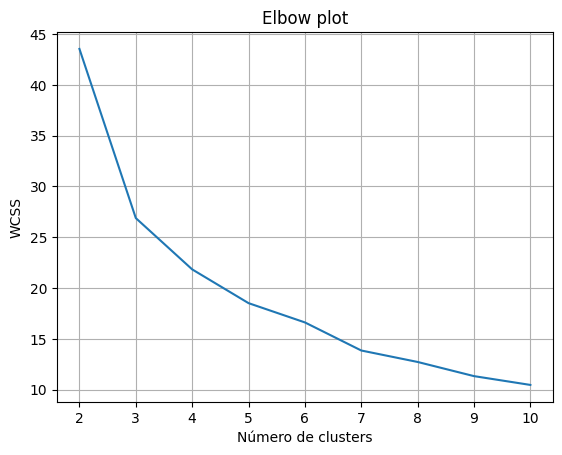

In [ ]:
from sklearn.cluster import KMeans

# calculamos cada KMean para cada número de clusters, y nos quedamos con el valor
wcss = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=10)
    kmeans.fit(features_data_2015)
    wcss.append(kmeans.inertia_)

# graficamos el elbow plot
plt.plot(range(2, 11), wcss)
plt.title('Elbow plot')
plt.grid("True")
plt.xlabel('Número de clusters')
plt.ylabel('WCSS')
plt.show()

En este gráfico vemos que quizá la elección de $K=4$ era la correcta. Eventualmente podríamos explorar algunos otros valores más altos y ver a qué conclusiones podemos arribar.

## 3 - Clustering Jerárquico

El algoritmo de clustering jerárquico construye los clusters iterativamente y de manera jerárquica, lo que nos permite evitar tener que elegir el número de clusters para construirlos.

Existen dos formas de hacerlo: aglomerativa o divisiva. En el enforme aglomerativo tomamos diferentes pares de muestras y las unimos según qué tan cerca se encuentren entre sí, hasta unirlas a todas en un único clúster. Más en detalle:

1. Al principio, tratamos a cada punto como un cluster. O sea, tenemos K = N clusters.
2. Formamos un cluster uniendo a los dos puntos más cercanos. Esto nos reduce el número de clusters a K = N-1.
3. Formamos más clusters uniendo los dos clusters más cercanos entre sí. Podemos comparar muestras entre sí, o muestras con clusters o clusters. Cómo hacemos esa comparación depende del criterio de enlace que utilicemos.
4. Repetimos los pasos de 2 a 3 hasta que todo nos queda en un único cluster.

Iterativamente podemos ir construyendo una representación gráfica conocida como dendrograma, en donde unimos las muestras entre sí según vayamos poniéndolas en un mismo cluster, y donde representamos las uniones con una altura equivalente a la distancia euclidea entre los elementos que se unen.

En el siguiente ejemplo vamos a construir un dendograma usando ```scipy```. Necesitamos importar las funciones ```linkage``` (que realiza el clustering aglomerativo y nos deja los datos listos para construir el dendrograma) y ```dendrogram``` (que nos permite graficarlo).

```linkage``` nos pide un parámetro, ```method```, que corresponde al criterio de enlace, o la estrategia utilizada para calcular la distancia entre nuevos clusters. Siempre unimos clusters con distancia mínima entre sí, pero el valor que utilizamos para comparar puede cambiar:
* Si usamos ```single```, calculamos todas las distancias entre todos los puntos de los dos clusters que analizamos, nos quedamos con la mínima, y eso es lo que vamos comparando.
* Si usamos ```complete```, hacemos lo mismo pero con la máxima distancia entre muestras.
* Si usamos ```average```, el promedio.
* Si usamos ```weighted```, calculamos la distancia entre los dos subclusters que uní previamente y el nuevo cluster al que estoy considerando unirme, y tomo el promedio de esos dos.
*Si uso ```centroid```, comparo distancia entre centroides.

Y así... Hay montones de variantes.

Usemos la más sencilla, comparar por distancia mínima a las muestras. Podríamos probar otras, si quisiéramos, modificando ```method``` en el código.

También tenemos la variable ```metric```, que nos permite elegir entre múltiples medidas de distancia. [Acá pueden ver todas las que están implementadas](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.linkage.html).

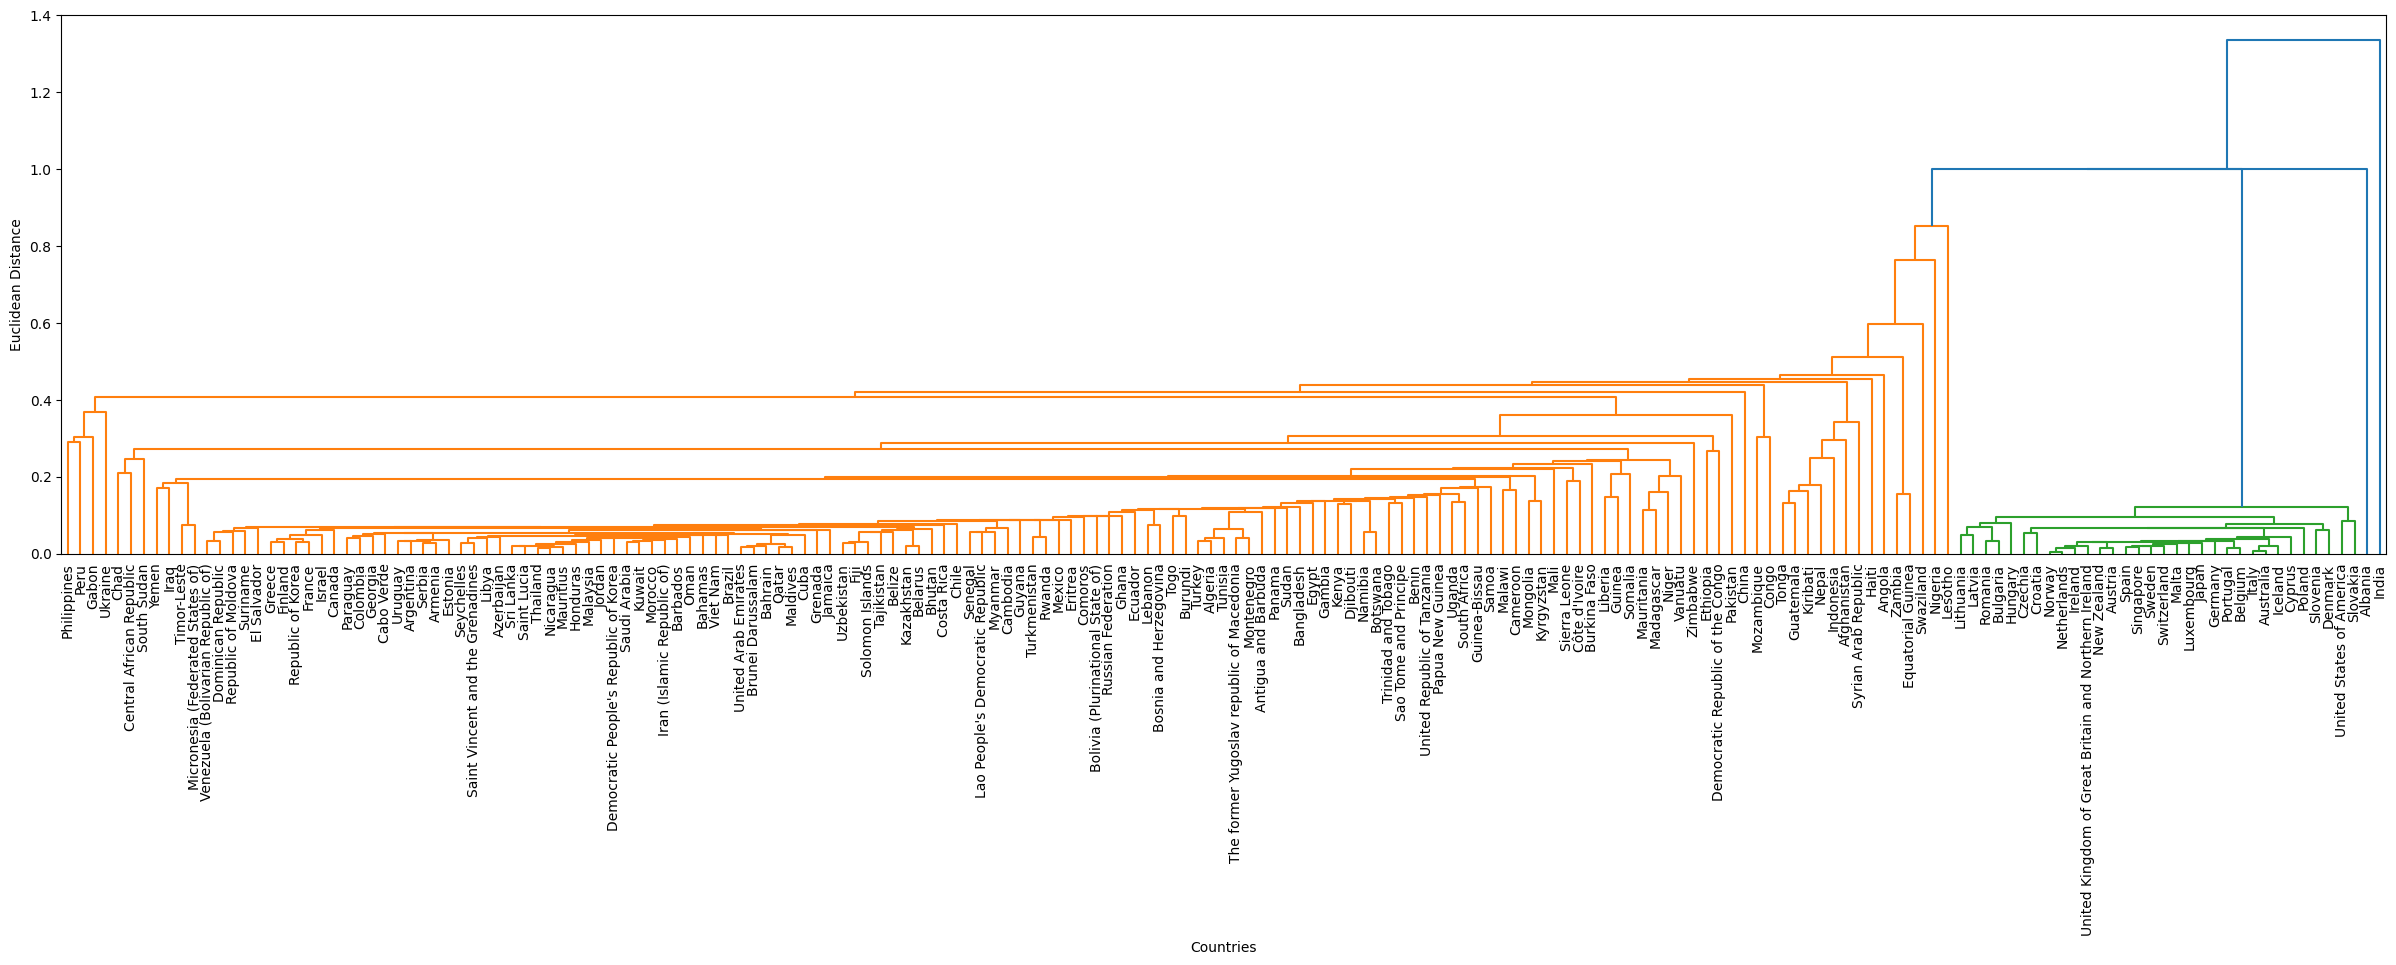

In [ ]:
from scipy.cluster.hierarchy import dendrogram, linkage

# generamos el clustering jerárquico
linked = linkage(features_data_2015, metric="euclidean", method='single')

# ploteamos el dendrograma
plt.figure(figsize=(30,7))
dendrogram(linked,
           orientation='top',
           labels=list(countries), # ojo que hay que pasarle una lista
           distance_sort='descending',
           show_leaf_counts=True,
           leaf_font_size=10)
plt.xlabel('Countries')
plt.ylabel('Euclidean Distance')
plt.show()

Podemos observar que existen algunos grupos claramente distinguibles entre sí (los marcados con diferentes colores). También podemos ver que India y Albania son dos países con bastantes diferencias respecto al resto, y que cuesta mucho unirlos con los demás. Esto nos indica que ambos son outliers, y puede deberse a varios factores: errores estadísticos, formas de medición diferentes, o simplemente países cuyas características son realmente muy diferentes al resto.

Si quisiéramos elegir una solución en particular, deberíamos trazar una línea horizontal en un valor de distancia euclídea e identificar el número de clusters resultantes. Por ejemplo, si la trazáramos en 0.8, tendríamos 5 clusters: uno para solamente la India, otro para Albania, otro para los países en verde, una para Lesotho y un último donde quedarían todos los países en rojo.

Para recuperar efectivamente esos mismos clusters, debemos aplicar el clustering aglomerativo una vez más. Para aprender otra forma de hacerlo, hagámoslo ahora usando Sklearn, que incluye ```AgglomerativeClustering```. Con ```metric``` determinamos la medida de distancia que queremos usar (por defecto es "euclidean", [pero tienen un montón de otras que pueden estudiar](https://scikit-learn.org/dev/modules/generated/sklearn.cluster.AgglomerativeClustering.html)), mientras que con ```linkage``` determinamos el criterio de unión entre clusters. Usemos ```single``` para coincidir con la partición anterior.

Si no queremos hacer dos pasos (```fit``` y ```predict```) podemos usar el método ```fit_predict``` para hacer las dos cosas a la vez.

In [ ]:
from sklearn.cluster import AgglomerativeClustering

# creamos el objeto para el clustering aglomerativo, eliminamos affinity porque no es necesario con linkage='single'
agglomerative = AgglomerativeClustering(n_clusters=2, metric="euclidean", linkage='single')
# usamos fit predict para buscar los clusters y devolverlos
clusters_agglomerative1 = agglomerative.fit_predict(features_data_2015)

# imprimimos por pantalla los nombres de los países asignados a cada cluster
for k in np.unique(clusters_agglomerative):
  print('Cluster {}'.format(k))
  print(countries[clusters_agglomerative==k])
  print('======')

Cluster 0
0                              Afghanistan
32                                 Algeria
48                                  Angola
64                     Antigua and Barbuda
80                               Argentina
                       ...                
2858    Venezuela (Bolivarian Republic of)
2874                              Viet Nam
2890                                 Yemen
2906                                Zambia
2922                              Zimbabwe
Name: Country, Length: 148, dtype: object
Cluster 1
112                                             Australia
128                                               Austria
240                                               Belgium
384                                              Bulgaria
641                                               Croatia
673                                                Cyprus
689                                               Czechia
737                                               Denmark
9

Podemos ver que efectivamente obtuvimos los clusters que habíamos visto al trazar la línea imaginaria vertical. Eventualmente podríamos buscar otras particiones y ver qué nos representan, o usar una gráfica t-SNE para observar los datos.

Podemos obviamente jugar con el tipo de distancia con la que trabajamos, y estudiar el efecto que este cambio tiene sobre los resultados. Veamos qué pasa en este caso cambiando por una distancia coseno:

In [ ]:
from sklearn.cluster import AgglomerativeClustering

# creamos el objeto para el clustering aglomerativo, eliminamos affinity porque no es necesario con linkage='single'
agglomerative = AgglomerativeClustering(n_clusters=5, metric="cosine", linkage='single')
# usamos fit predict para buscar los clusters y devolverlos
clusters_agglomerative = agglomerative.fit_predict(features_data_2015)

# imprimimos por pantalla los nombres de los países asignados a cada cluster
for k in np.unique(clusters_agglomerative):
  print('Cluster {}'.format(k))
  print(countries[clusters_agglomerative==k])
  print('======')

Cluster 0
0                              Afghanistan
32                                 Algeria
48                                  Angola
64                     Antigua and Barbuda
80                               Argentina
                       ...                
2842                               Vanuatu
2858    Venezuela (Bolivarian Republic of)
2874                              Viet Nam
2890                                 Yemen
2922                              Zimbabwe
Name: Country, Length: 178, dtype: object
Cluster 1
834     Equatorial Guinea
2906               Zambia
Name: Country, dtype: object
Cluster 2
1186    India
Name: Country, dtype: object
Cluster 3
1893    Nigeria
Name: Country, dtype: object
Cluster 4
16    Albania
Name: Country, dtype: object


## 4 - "Evaluación" de las soluciones

Cuando evaluamos algo, normalmente lo que hacemos es comparar contra el valor que esperábamos correcto. Así, por ejemplo, si yo quiero evaluar si rendí bien un examen, tengo que comparar mis respuestas con las respuestas que se sabe que son correctas.

Pero evaluar un método de clustering es algo más complicado, porque no tenemos etiquetas que me definan específicamente cuál es la solución correcta. No sabemos cuáles son los grupos correctos, los estamos descubriendo en el momento, y encima en un espacio de alta dimensionalidad que solamente podemos estudiar graficamente si lo proyectamos a dos dimensiones. Por ende no hay forma de determinar si la solución que obtuvimos (la partición en clusters) es la correcta. Sin embargo, existen algunas heurísticas que podemos aplicar para, al menos, estudiar qué tan bien distribuidos están esos clusters, y eventualmente decidir si me quedo con eso para un estudio más detallado de los resultados, o si prefiero seguir trabajando en los parámetros de los algoritmos.

Vamos a evaluar los clusterings que construimos en función de las siguientes métricas:

* Índice de Davies Bouldin (cuanto más bajo, mejor): $DB = \frac{1}{k} \sum_{i=1}^{k} \max_{j \neq i} \left( \frac{S_i + S_j}{d_{ij}} \right)$, donde $k$ es el número de clusters, $S_i$ es la dispersión dentro del cluster, que se calcula como $S_i = \frac{1}{|C_i|} \sum_{x \in C_i} \left\| x - c_i \right\|$, y $d_ij$ es la distancia entre los centroides de los clusters $i$ y $j$.
* Coeficiente de silueta (cuanto más cerca de 1, mejor; cuando más cerca de -1, peor): $s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$, donde $a(i)$ es la distancia promedio entre el punto
$i$ y todos los demás puntos del mismo cluster, y $b(i)$ es la distancia promedio entre el punto $i$ y los puntos del cluster más cercano (al que $i$ no pertenece).

No usaremos el índice de Dunn porque no está implementado en Sklearn :(

K-means
DB score: 0.9950
Silhouette score: 0.5084
----------
Hierarchical Clustering
DB score: 0.4500
Silhouette score: 0.3048
----------


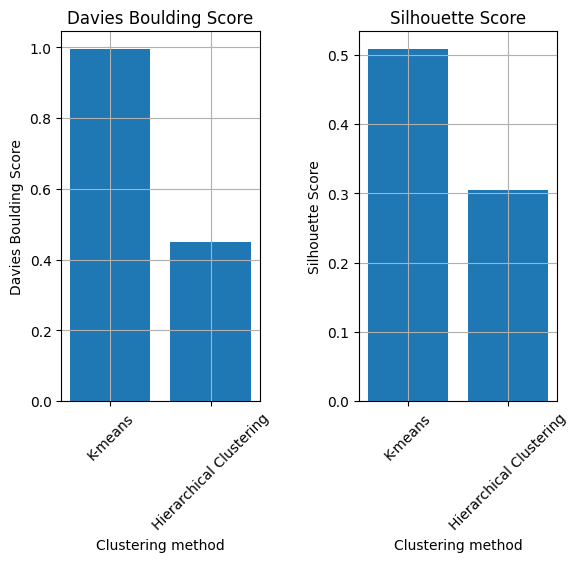

In [ ]:
from sklearn.metrics import davies_bouldin_score, silhouette_score

# inicializamos listas con los resultados de cada algoritmo y los nombres de los
# algoritmos
clusters_to_compare = [clusters_kmeans, clusters_agglomerative]
clustering_methods = ['K-means', 'Hierarchical Clustering']

# inicializamos vectores donde iremos guardando los resultados
db_scores = np.zeros(len(clusters_to_compare))
silhouette_scores = np.zeros(len(clusters_to_compare))

# por cada uno de los métodos
for i in range(len(clusters_to_compare)):
  # calculamos las métricas
  db_scores[i] = davies_bouldin_score(features_data_2015, clusters_to_compare[i])
  silhouette_scores[i] = silhouette_score(features_data_2015, clusters_to_compare[i])
  # las imprimimos
  print(clustering_methods[i])
  print('DB score: {:.4f}'.format(db_scores[i]))
  print('Silhouette score: {:.4f}'.format(silhouette_scores[i]))
  print('----------')

# inicializamos un gráfico para cada métrica
fig, axes = plt.subplots(1, 2)
plt.subplots_adjust(wspace=0.5)
# graficamos el Davies Bouldin score
axes[0].bar(np.arange(db_scores.size), db_scores)
axes[0].set_title('Davies Boulding Score')
axes[0].set_xlabel('Clustering method')
axes[0].set_ylabel('Davies Boulding Score')
axes[0].set_xticks(np.arange(db_scores.size))
axes[0].set_xticklabels(clustering_methods, rotation=45)
axes[0].grid(True)
# y el Silhouette Score
axes[1].bar(np.arange(silhouette_scores.size), silhouette_scores)
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Clustering method')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_xticks(np.arange(silhouette_scores.size))
axes[1].set_xticklabels(clustering_methods, rotation=45)
axes[1].grid(True)

plt.show()

Vemos que en este caso logramos que el método de clustering jerárquico supere significativamente al de K-means en términos del Davies Boulding score. Esto implica que los clusters que encontramos con este método están mejor separados entre sí y son más densos internamente. Tengamos en cuenta que esa "densidad" puede deberse en parte a que tenemos algunos clusters con solamente 1 muestra. Esos clusters pueden demandar un análisis por separado: ¿qué pasa con India y Albania que se comportan tan diferente al resto de los países? Para responder esa pregunta deberíamos analizar las features individualmente, compararlas entre países, y hablar con sanitaristas y sociólogos para entender más acerca de esas diferencias.

Bueno, eso es todo por hoy. Tributando a como vengo cerrando todos los Colabs, les cuento que es martes, son las 18:29, estoy en el patio con la compu aprovechando los primeros soles primaverales. Y revisándoles el Colab. ASÍ QUE MÁS VALE QUE LO USEN! Y tomen nota en clase también, che. :P
